# 01 — Tiền xử lý dữ liệu Seafar

Seafar chứa chuỗi IMU/GPS với timestamp thực; báo cáo audit ghi nhận timestamp trùng và các khoảng gián đoạn. Rate fields có tên đơn vị rad/min nhưng lineage trục và phần cứng cần thận trọng.

Notebook này trình bày kết quả pipeline hiện hữu; không sửa raw data, không tái xử lý/ghi đè Parquet, không trích xuất feature, gán nhãn hoặc huấn luyện mô hình. Không diễn giải rate theo tên trường như gyro đã xác nhận về phần cứng/trục.

## 1. Thiết lập và nạp cấu hình

Các đường dẫn được phân giải tương đối từ repository root. Dữ liệu raw được đọc bằng loader trong `ml.preprocessing`; báo cáo và Parquet được tái sử dụng từ lần chạy pipeline đã lưu.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm repository root để notebook chạy từ thư mục gốc hoặc thư mục con.
def find_repo_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml/preprocessing").is_dir() and (candidate / "ml/reports/preprocessing/preprocessing_summary.json").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy repository SVMG hoặc báo cáo preprocessing.")

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SUMMARY_PATH = ROOT / "ml/reports/preprocessing/preprocessing_summary.json"
summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
CONFIG_PATH = ROOT / "ml/preprocessing/config.yaml"
from ml.preprocessing.config import load_config
config = load_config(CONFIG_PATH)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.autolayout": True})

def repo_relative(path):
    candidate = Path(path)
    if candidate.is_absolute():
        try:
            candidate = candidate.resolve().relative_to(ROOT)
        except ValueError:
            # Hỗ trợ summary cũ từ clone khác bằng cách lấy phần bắt đầu tại ml/.
            parts = candidate.parts
            if "ml" not in parts:
                raise
            candidate = Path(*parts[parts.index("ml"):])
    return (ROOT / candidate).resolve().relative_to(ROOT).as_posix()

DATASET = "seafar"


## 2. Giới thiệu nguồn và kiểm tra raw data

Cell tiếp theo nạp một nguồn dữ liệu qua loader hiện hữu, hiển thị schema và một preview nhỏ. Không đưa toàn bộ dữ liệu vào output notebook.

In [2]:
from ml.preprocessing.seafar import load_sessions as load_seafar
from ml.preprocessing.hohai import load_sessions as load_hohai
from ml.preprocessing.southampton import load_sessions as load_southampton

loaders = {"seafar": load_seafar, "hohai": load_hohai, "southampton": load_southampton}
raw_sessions = loaders[DATASET](ROOT / "ml/data/raw")
dataset_summary = summary["datasets"][DATASET]
# Chọn segment đầu ra dài nhất để minh họa; không nối các segment.
artifacts = [item for item in summary["artifact_inventory"] if f"/{DATASET}/" in item["data_path"].replace("\\", "/")]
selected_artifact = max(artifacts, key=lambda item: item["rows"])
processed_path = ROOT / repo_relative(selected_artifact["data_path"])
processed = pd.read_parquet(processed_path)
selected_session_id = str(processed["session_id"].iloc[0])
raw_session = next(session for session in raw_sessions if session.session_id == selected_session_id)
raw_report = next(item for item in dataset_summary["session_summaries"] if item["session_id"] == selected_session_id)
print(f"[THÔNG TIN] Nguồn: {DATASET}; phiên minh họa: {selected_session_id}; segment: {processed['segment_id'].iloc[0]}")
print(f"[THÔNG TIN] Tệp Parquet: {repo_relative(processed_path)} ({len(processed):,} hàng)")


[THÔNG TIN] Nguồn: seafar; phiên minh họa: seafar_session_001; segment: segment_002
[THÔNG TIN] Tệp Parquet: ml/data/processed/seafar/seafar_session_001/segment_002/timeseries.parquet (59,921 hàng)


In [3]:
# Cấu trúc phiên và schema tín hiệu đã được loader hiện hữu ánh xạ.
structure = pd.DataFrame([
    {"Trường": "dataset_source", "Giá trị": raw_session.dataset_source},
    {"Trường": "session_id", "Giá trị": raw_session.session_id},
    {"Trường": "raw_reference", "Giá trị": Path(raw_session.raw_reference.split("::")[0]).name},
    {"Trường": "số hàng gốc", "Giá trị": raw_session.original_row_count},
    {"Trường": "Sampling Rate ước tính/được ghi nhận (Hz)", "Giá trị": raw_report["input_sampling_hz"]},
    {"Trường": "nguồn timestamp", "Giá trị": raw_session.provenance.get("timestamp_source")},
    {"Trường": "các tín hiệu ánh xạ", "Giá trị": ", ".join(raw_session.signals.keys())},
])
display(structure)

raw_preview = pd.DataFrame({"time_seconds": raw_session.time_seconds})
for signal_name in ("roll_deg", "pitch_deg", "gyro_x_rad_s", "gyro_y_rad_s", "accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2"):
    if signal_name in raw_session.signals:
        raw_preview[signal_name] = raw_session.signals[signal_name]
print("8 hàng đầu của phiên minh họa (không nhúng toàn bộ dữ liệu vào notebook):")
display(raw_preview.head(8))
missing_preview = pd.DataFrame({"Tín hiệu": list(raw_session.signals),
    "Thiếu hoặc không hữu hạn (%)": [round(float((~np.isfinite(values)).mean() * 100), 4) for values in raw_session.signals.values()]})
display(missing_preview)


,Trường,Giá trị
0,dataset_source,seafar
1,session_id,seafar_session_001
2,raw_reference,cleaned_imu_gps_data.json
3,số hàng gốc,143318
4,Sampling Rate ước tính/được ghi nhận (Hz),10.00001
5,nguồn timestamp,datetime Unix epoch milliseconds
6,các tín hiệu ánh xạ,"roll_deg, pitch_deg, gyro_x_rad_s, gyro_y_rad_..."


8 hàng đầu của phiên minh họa (không nhúng toàn bộ dữ liệu vào notebook):


,time_seconds,roll_deg,pitch_deg,gyro_x_rad_s,gyro_y_rad_s,accel_x_m_s2,accel_y_m_s2,accel_z_m_s2
0,1.644921e+09,2.97,0.65,0.000333,-0.000167,0.00695,-0.01537,0.00873
1,1.644921e+09,2.97,0.65,0.000167,0.000167,-0.01376,0.00150,0.01191
2,1.644921e+09,2.97,0.65,-0.000167,-0.000167,-0.00578,-0.00941,0.01227
3,1.644921e+09,2.97,0.65,0.000167,0.000000,-0.00374,-0.01151,0.01017
4,1.644921e+09,2.96,0.65,0.000833,0.000000,0.00015,-0.00170,0.00898
5,1.644921e+09,2.96,0.65,0.000167,0.000167,-0.00679,-0.00848,0.01068
6,1.644921e+09,2.95,0.65,0.000833,-0.000333,0.00386,-0.01166,0.00824
7,1.644921e+09,2.95,0.65,0.000833,0.000000,-0.00718,-0.00787,0.00226


,Tín hiệu,Thiếu hoặc không hữu hạn (%)
0,roll_deg,0.0
1,pitch_deg,0.0
2,gyro_x_rad_s,0.0
3,gyro_y_rad_s,0.0
4,yaw_deg,0.0
5,accel_x_m_s2,0.0
6,accel_y_m_s2,0.0
7,accel_z_m_s2,0.0
8,heading_deg,0.0
9,latitude_deg,0.0


## 3. Đánh giá chất lượng dữ liệu

Các phép kiểm tra được thực hiện trong `common.py`, loader theo nguồn và `quality_checks.py`; notebook trình bày kết quả đã ghi trong summary, không cài đặt lại chính sách làm sạch.

In [4]:
quality_fields = [
    ("rows_before", "Số hàng đầu vào"), ("rows_after_duplicate_resolution", "Sau xử lý timestamp trùng"),
    ("rows_after_required_validation", "Sau kiểm tra trường bắt buộc"), ("rows_output", "Số hàng đầu ra"),
    ("rows_removed_exact_duplicates", "Duplicate đồng nhất đã bỏ"),
    ("rows_removed_conflicting_duplicate_groups", "Hàng trong nhóm timestamp xung đột đã bỏ"),
    ("invalid_required_rows_removed", "Hàng thiếu/không hợp lệ ở trường bắt buộc"),
    ("gap_count", "Số khoảng gián đoạn"), ("continuous_segments_detected", "Segment liên tục phát hiện"),
    ("sampling_irregularity_median_ratio", "Tỷ lệ jitter trung vị"),
    ("input_duration_seconds", "Span thời lượng phiên (s)"),
]
quality_table = pd.DataFrame([{"Kiểm tra": label, "Kết quả thực tế": raw_report.get(key)} for key, label in quality_fields])
display(quality_table)
print("Cảnh báo của loader:")
for warning in raw_session.warnings:
    print(f"- {warning}")


test_results = summary["test_results"]
print("Kết quả kiểm thử tự động gần nhất được ghi trong summary:")
display(pd.DataFrame([{"Tổng bài": test_results["total"], "Đạt": test_results["passed"],
    "Không đạt": test_results["failed"], "Bỏ qua": test_results["skipped"],
    "Lệnh": test_results["command"], "Kết quả": test_results["result_summary"]}]))


,Kiểm tra,Kết quả thực tế
0,Số hàng đầu vào,143318.0
1,Sau xử lý timestamp trùng,143290.0
2,Sau kiểm tra trường bắt buộc,143290.0
3,Số hàng đầu ra,143264.0
4,Duplicate đồng nhất đã bỏ,0.0
5,Hàng trong nhóm timestamp xung đột đã bỏ,28.0
6,Hàng thiếu/không hợp lệ ở trường bắt buộc,0.0
7,Số khoảng gián đoạn,31.0
8,Segment liên tục phát hiện,32.0
9,Tỷ lệ jitter trung vị,0.0


Cảnh báo của loader:
- Các trường rate có tên đơn vị rad/min; chưa tìm thấy tài liệu cảm biến xác nhận nguồn phần cứng, trục và quy ước dấu.
- Giữ nguyên dấu; ánh xạ roll/pitch rate sang trục x/y chỉ là ánh xạ theo tên trường.
Kết quả kiểm thử tự động gần nhất được ghi trong summary:


,Tổng bài,Đạt,Không đạt,Bỏ qua,Lệnh,Kết quả
0,18,18,0,0,python -m pytest ml/preprocessing/tests -q,18 passed in 1.62s


## 4. Phương pháp Data Preprocessing

Tham số cụ thể được nạp từ `ml/preprocessing/config.yaml`. Duplicate cùng timestamp nhưng xung đột được loại theo nhóm; gap tách segment; không nội suy xuyên gap. Nguồn 50 Hz được lọc causal trước khi giảm xuống target rate. Hohai dùng timestamp suy từ sample index; gyro thiếu được để null.

## 5. So sánh thống kê trước và sau xử lý

Các giá trị dưới đây lấy trực tiếp từ báo cáo pipeline, gồm mean, population standard deviation, min/max, percentile, RMS và peak-to-peak.

In [5]:
# Bảng thống kê này đọc trực tiếp summary JSON do pipeline hiện hữu sinh ra.
stat_rows = []
for signal, label in (("roll_deg", "Roll (độ)"), ("pitch_deg", "Pitch (độ)")):
    for metric, metric_label in (("mean", "Trung bình"), ("std_population", "Độ lệch chuẩn tổng thể"),
        ("min", "Nhỏ nhất"), ("max", "Lớn nhất"), ("p05", "Phân vị 5%"), ("p50", "Trung vị"),
        ("p95", "Phân vị 95%"), ("rms", "RMS"), ("peak_to_peak", "Đỉnh-đỉnh")):
        stat_rows.append({"Tín hiệu": label, "Thống kê": metric_label,
            "Trước xử lý": dataset_summary["statistics_before"][signal][metric],
            "Sau xử lý": dataset_summary["statistics_after"][signal][metric]})
comparison = pd.DataFrame(stat_rows)
display(comparison.style.format({"Trước xử lý": "{:.6g}", "Sau xử lý": "{:.6g}"}))


,Tín hiệu,Thống kê,Trước xử lý,Sau xử lý
0,Roll (độ),Trung bình,3.31319,3.31318
1,Roll (độ),Độ lệch chuẩn tổng thể,0.23509,0.235087
2,Roll (độ),Nhỏ nhất,2.18,2.18
3,Roll (độ),Lớn nhất,4.65,4.65
4,Roll (độ),Phân vị 5%,2.96,2.96
5,Roll (độ),Trung vị,3.3,3.3
6,Roll (độ),Phân vị 95%,3.7,3.7
7,Roll (độ),RMS,3.32152,3.32151
8,Roll (độ),Đỉnh-đỉnh,2.47,2.47
9,Pitch (độ),Trung bình,0.840076,0.840055


## 6. Biểu đồ Roll/Pitch trước và sau

Biểu đồ dùng phiên raw tương ứng với segment đầu ra dài nhất của nguồn này; chỉ vẽ phần timestamp giao nhau. Đây là minh họa trên phiên cụ thể, không đại diện mọi phiên.

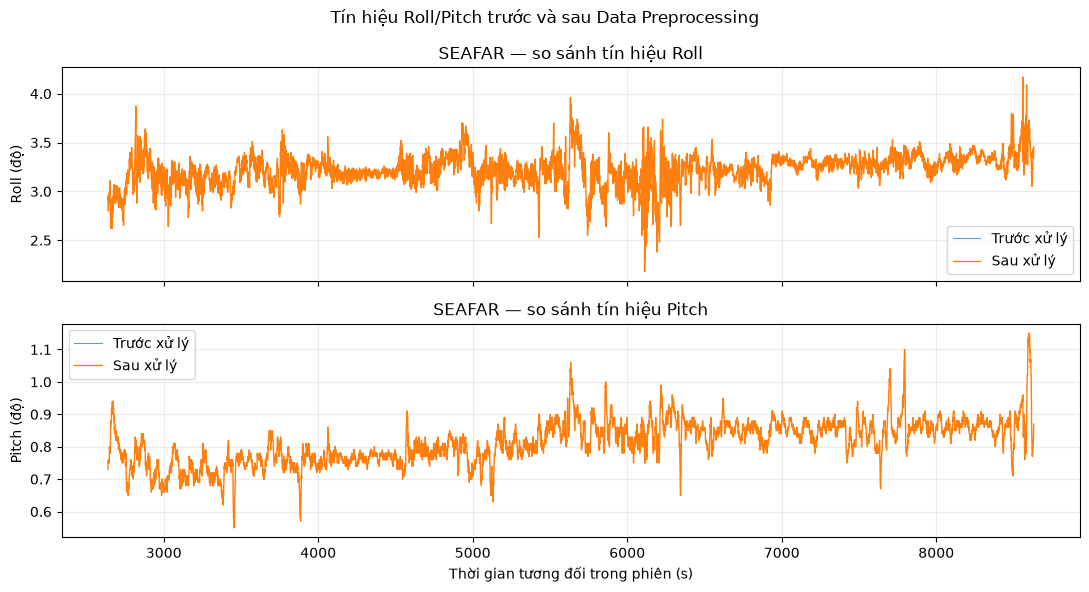

In [6]:
# So sánh cùng khoảng thời gian của đúng phiên và segment; dữ liệu thô không bị sửa.
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
processed_start = float(processed["time_seconds"].min())
processed_end = float(processed["time_seconds"].max())
raw_t = np.asarray(raw_session.time_seconds, dtype=float)
raw_order = np.argsort(raw_t, kind="stable")
raw_t = raw_t[raw_order]
for ax, signal, label in zip(axes, ("roll_deg", "pitch_deg"), ("Roll", "Pitch")):
    raw_values = np.asarray(raw_session.signals[signal], dtype=float)[raw_order]
    mask = np.isfinite(raw_t) & np.isfinite(raw_values) & (raw_t >= processed_start) & (raw_t <= processed_end)
    ax.plot(raw_t[mask], raw_values[mask], label="Trước xử lý", linewidth=.8, alpha=.7)
    ax.plot(processed["time_seconds"], processed[signal], label="Sau xử lý", linewidth=1.0)
    ax.set_title(f"{DATASET.upper()} — so sánh tín hiệu {label}")
    ax.set_ylabel(f"{label} (độ)")
    ax.grid(True, alpha=.25)
    ax.legend()
axes[-1].set_xlabel("Thời gian tương đối trong phiên (s)")
fig.suptitle("Tín hiệu Roll/Pitch trước và sau Data Preprocessing")
plt.show()


## 7. Chẩn đoán lọc và resampling

Bảng band-power đọc số liệu chẩn đoán của pipeline. PSD phía dưới được tính từ mẫu raw cùng khoảng thời gian và Parquet tương ứng để trực quan hóa. Seafar không được upsample hoặc lọc giảm mẫu khi nguồn xấp xỉ 10 Hz.

Nguồn này không cần giảm Sampling Rate bằng anti-alias filter; không có chỉ số lọc 50→10 Hz.
Cấu hình pipeline đang dùng:


,Tham số,Giá trị
0,target_sampling_hz,10.0
1,maximum_gap_factor,1.5
2,duplicate_tolerance,0.0
3,filter_order,4
4,anti_alias_cutoff_hz,4.0
5,filter_warmup_seconds,2.0
6,valid_fraction_threshold,0.95
7,minimum_segment_seconds,1.0
8,quantile_method,type7
9,timestamp_origin_hohai,INFERRED_FROM_SAMPLE_INDEX


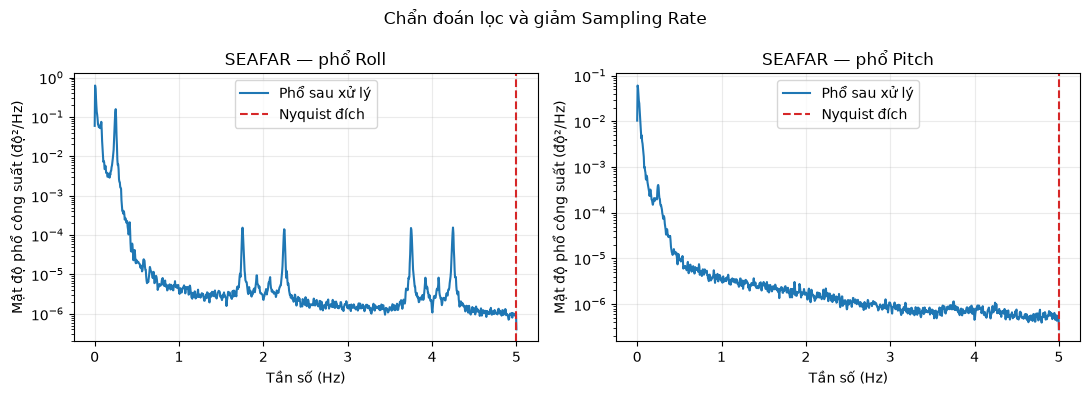

In [7]:
# Các chỉ số band-power/anti-alias lấy trực tiếp từ kiểm định trên từng segment.
frequency_rows = []
for record in dataset_summary["frequency_diagnostics"]:
    for signal, label in (("roll_deg", "Roll"), ("pitch_deg", "Pitch")):
        result = record.get(signal)
        if result:
            frequency_rows.append({"Tín hiệu": label, "Sampling Rate nguồn (Hz)": result["source_rate_hz"],
                "Sampling Rate đích (Hz)": result["target_rate_hz"],
                "Tỷ lệ công suất dải thấp 0,1–2 Hz": result["low_band_power_ratio"],
                "Suy giảm ngoài dải (dB)": result["out_of_band_attenuation_db"]})
if frequency_rows:
    frequency_table = pd.DataFrame(frequency_rows)
    display(frequency_table.groupby("Tín hiệu").agg({
        "Sampling Rate nguồn (Hz)": "median", "Sampling Rate đích (Hz)": "median",
        "Tỷ lệ công suất dải thấp 0,1–2 Hz": "median", "Suy giảm ngoài dải (dB)": "median"}).round(5))
else:
    print("Nguồn này không cần giảm Sampling Rate bằng anti-alias filter; không có chỉ số lọc 50→10 Hz.")

print("Cấu hình pipeline đang dùng:")
display(pd.DataFrame([{"Tham số": key, "Giá trị": value} for key, value in config["preprocessing"].items()]))

# PSD được tính để minh họa chẩn đoán; không thay đổi tín hiệu hay tạo artifact preprocessing mới.
from scipy.signal import welch
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw_mask = np.isfinite(raw_t) & (raw_t >= processed_start) & (raw_t <= processed_end)
fs_raw = raw_report["input_sampling_hz"] or 10.0
fs_processed = dataset_summary["sampling_rate_after_hz_median"] or 10.0
for ax, signal, label in zip(axes, ("roll_deg", "pitch_deg"), ("Roll", "Pitch")):
    raw_values = np.asarray(raw_session.signals[signal], dtype=float)[raw_order][raw_mask]
    raw_values = raw_values[np.isfinite(raw_values)]
    processed_values = processed[signal].to_numpy(dtype=float)
    processed_values = processed_values[np.isfinite(processed_values)]
    if len(raw_values) >= 32:
        f_raw, p_raw = welch(raw_values, fs=fs_raw, nperseg=min(2048, len(raw_values)))
        ax.semilogy(f_raw, p_raw, label="Phổ trước xử lý")
    if len(processed_values) >= 32:
        f_processed, p_processed = welch(processed_values, fs=fs_processed, nperseg=min(2048, len(processed_values)))
        ax.semilogy(f_processed, p_processed, label="Phổ sau xử lý")
    ax.axvline(fs_processed / 2, color="tab:red", linestyle="--", label="Nyquist đích")
    ax.set_title(f"{DATASET.upper()} — phổ {label}")
    ax.set_xlabel("Tần số (Hz)")
    ax.set_ylabel("Mật độ phổ công suất (độ²/Hz)")
    ax.grid(True, alpha=.25)
    ax.legend()
fig.suptitle("Chẩn đoán lọc và giảm Sampling Rate")
plt.show()


## 8. Kiểm định chất lượng và window eligibility

Cửa sổ được tính riêng trong từng segment; không nối qua gap hoặc phiên khác. Điều kiện này không đồng nghĩa với nhãn hoặc đánh giá an toàn.

In [8]:
sessions_table = pd.DataFrame([{
    "Phiên": item["session_id"], "Số hàng đầu vào": item["rows_before"],
    "Sampling Rate (Hz)": item["input_sampling_hz"], "Thời lượng phiên (s)": item["input_duration_seconds"],
    "Segment liên tục": item["continuous_segments_detected"], "Đủ 60 s": item["eligible_60s_segments"],
    "Đủ 180 s": item["eligible_180s_segments"], "Cảnh báo": "; ".join(item["warnings"])
} for item in dataset_summary["session_summaries"]])
print(f"Tổng số phiên: {dataset_summary['session_count']}; đủ 60 s: {dataset_summary['eligible_60s_segments']}; đủ 180 s: {dataset_summary['eligible_180s_segments']}.")
print("Các phiên đủ cửa sổ 180 s:")
display(sessions_table[sessions_table["Đủ 180 s"] > 0].reset_index(drop=True))
print("Phiên minh họa có bao phủ cửa sổ:")
display(sessions_table[sessions_table["Phiên"] == selected_session_id].reset_index(drop=True))
print("Quy ước: window eligibility được kiểm tra riêng trên từng segment đầu ra; không cộng dồn qua gap hoặc session.")


Tổng số phiên: 1; đủ 60 s: 7; đủ 180 s: 4.
Các phiên đủ cửa sổ 180 s:


,Phiên,Số hàng đầu vào,Sampling Rate (Hz),Thời lượng phiên (s),Segment liên tục,Đủ 60 s,Đủ 180 s,Cảnh báo
0,seafar_session_001,143318,10.00001,14332.6,32,7,4,Các trường rate có tên đơn vị rad/min; chưa tì...


Phiên minh họa có bao phủ cửa sổ:


,Phiên,Số hàng đầu vào,Sampling Rate (Hz),Thời lượng phiên (s),Segment liên tục,Đủ 60 s,Đủ 180 s,Cảnh báo
0,seafar_session_001,143318,10.00001,14332.6,32,7,4,Các trường rate có tên đơn vị rad/min; chưa tì...


Quy ước: window eligibility được kiểm tra riêng trên từng segment đầu ra; không cộng dồn qua gap hoặc session.


## Giải thích kỹ thuật phục vụ vấn đáp

### Đọc dữ liệu và chuẩn hóa schema
- **Em làm gì?** Dùng loader hiện hữu của nguồn để ánh xạ cột sang `RawSession`, sau đó đọc Parquet đã được pipeline tạo.
- **Vì sao?** Ba nguồn có schema và timestamp khác nhau; dùng chung loader giúp notebook nhất quán với kết quả pipeline.
- **Kết quả thực tế?** Bảng cấu trúc, preview 8 hàng và missing summary ở trên đến từ phiên raw thật; bảng thống kê trước/sau lấy từ `preprocessing_summary.json`.
- **Nếu bỏ qua?** Dễ dùng nhầm cột, đơn vị hoặc ranh giới phiên.
- **Giới hạn?** Preview chỉ minh họa, không đại diện toàn bộ phân bố; Hohai dùng thời gian suy từ chỉ số mẫu.

### Duplicate, missing và phân đoạn
- **Em làm gì?** Notebook đọc số liệu chất lượng do module chung ghi; duplicate xung đột bị loại cả nhóm, timestamp gap tạo segment riêng.
- **Vì sao?** Tránh trung bình các phép đo xung đột và tránh tạo cửa sổ xuyên đoạn mất dữ liệu.
- **Kết quả thực tế?** Bảng chất lượng nêu số hàng, duplicate, gap và segment của phiên minh họa.
- **Nếu bỏ qua?** Có thể sai thống kê và giả định dữ liệu liên tục khi không có quan sát.
- **Giới hạn?** Hohai không có timestamp thiết bị để quan sát dropout.

### Đổi đơn vị, lọc causal và resampling
- **Em làm gì?** Pipeline dùng cấu hình để áp dụng đổi đơn vị đã xác nhận; lọc Butterworth causal trước khi giảm 50 Hz xuống 10 Hz; notebook chỉ đọc kết quả và tái tính PSD để minh họa.
- **Vì sao?** Anti-aliasing giảm thành phần có thể gập phổ; causal filtering không dùng mẫu tương lai.
- **Kết quả thực tế?** Bảng band-power và biểu đồ phổ hiển thị mức giữ dải thấp/suy giảm ngoài dải trên dữ liệu thực.
- **Nếu bỏ qua?** Alias có thể làm sai tín hiệu sau giảm tần số; mapping rate sai đơn vị làm lệch scale.
- **Giới hạn?** Filter có phase delay và mất warmup; Seafar khoảng 10 Hz không có bước 50→10 Hz; trục/nguồn gyro Seafar và ngữ nghĩa Delta Angle Southampton còn cần xác nhận.

### Kiểm định và cửa sổ
- **Em làm gì?** Trình bày kết quả suite kiểm thử và window eligibility theo session/segment từ báo cáo pipeline.
- **Vì sao?** Đảm bảo các cửa sổ tương lai không vượt qua gap hoặc ranh giới run.
- **Kết quả thực tế?** Kết quả test và số phiên đủ 60/180 giây được lấy trực tiếp từ summary đã sinh.
- **Nếu bỏ qua?** Số lượng cửa sổ hợp lệ có thể bị thổi phồng bằng cách nối phiên.
- **Giới hạn?** Eligibility mô tả độ dài/continuity, không xác nhận chất lượng khoa học hoặc khả năng phát hiện nguy hiểm.


## Tài liệu và tái lập

- Báo cáo: `ml/reports/preprocessing/preprocessing_results.md`
- Summary máy đọc: `ml/reports/preprocessing/preprocessing_summary.json`
- Cấu hình: `ml/preprocessing/config.yaml`
- Hướng dẫn chạy pipeline/notebook: `ml/preprocessing/README.md`